# Ammonia Ignition Delay: Active Subspaces of the 123 Arrhenius Parameters of an Optimized Ammonia/Syngas Mechanism

__Wenyu Li__, School of Mechanical Engineering, Nanjing University of Science and Technology, Nanjing 210094, PR China; State Key Laboratory of Coal Combustion, Huazhong University of Science and Technology, Wuhan 430074, PR China

__Chun Zou__, State Key Laboratory of Coal Combustion, Huazhong University of Science and Technology, Wuhan 430074, PR China

__Hong Yao__, State Key Laboratory of Coal Combustion, Huazhong University of Science and Technology, Wuhan 430074, PR China

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. This is a **stored-data** set: the data were computed with [Cantera](https://cantera.org) 3.2.0, an outside code, by the included `generate_data.py` and `ammonia_idt_driver.py`; the shipped files are the record, and `DATA.md` gives their full provenance. Cantera is needed only to regenerate them. The notebook imports the driver only for its constants and the geometry of the input region, which need numpy alone.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import ammonia_idt_driver as drv  # names, bounds and region geometry (numpy only); solving needs Cantera

SEED = 2023                       # the only seed in this notebook (region share estimate, bootstrap)
t_start = time.perf_counter()
QOIS = drv.QOIS                   # conditions A, B, C

### Summary

Li, Zou and Yao [1] optimized the 123 Arrhenius parameters of 41 influential reactions in a 37-species ammonia/syngas mechanism, each reaction confined to a temperature-dependent uncertainty region around its rate constant. Here the 41 rate constants vary uniformly over a region of the paper's shape and width, re-centred on the optimized constants because the paper does not publish its nominal ones, and Cantera computes the ignition delay at three shock-tube and rapid-compression-machine conditions with finite-difference gradients at 100 Monte Carlo samples. At every condition one direction dominates the 123-dimensional input space (first eigenvalue ratios 32.0, 8.5 and 13.7 in the coordinates used here), and a quadratic in that single active variable predicts $\log_{10}\tau$ with leave-one-out $R^2$ of 0.9448, 0.9138 and 0.9278; the directions are led by NH3 + H = NH2 + H2 at 1850 K and by the NH2 + NO, NH2 + NO2 and H2NO + O2 reactions at the lower temperatures.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $\mathbf x\in[-1,1]^m$ with a density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [5].

### The model

**Mechanism.** The optimized ammonia/syngas mechanism of [1] (37 species and 237 reactions, p. 2073), from the CHEMKIN files of the paper's electronic supplementary information (ESI), converted to Cantera's format by `convert_mechanism.py` (`ammonia_syngas_optimized.yaml`). The mechanism file is not included in this data set; `DATA.md` gives the download and the conversion. This notebook does not need it. Rate constants have the modified Arrhenius form $k(T) = A\,T^{b}\exp(-E/RT)$ (p. 2074).

**The paper's uncertainty region.** The paper selected 41 influential reactions by sensitivity analysis and optimized all three Arrhenius parameters of each, 123 in all (Sec. 4.1, pp. 2074–2075; Table 2, p. 2076). For pressure-dependent reactions only the low-pressure-limit parameters were optimized (p. 2075; caption of Table 2); four of the 41 are falloff reactions (R03, R04, R06, R22), and their low-pressure limits are the ones varied here. Each rate constant is confined to the region of eqn (4), p. 2074,

$$\left|\log_{10}\frac{k(T)}{k_0(T)}\right| \le f(T),$$

which, with $\alpha = \ln(A/A_0)$, $\beta = b - b_0$ and $\varepsilon = (E-E_0)/R$, is eqn (5), p. 2074:

$$-f(T)\ln 10 \le \alpha + \beta\ln T - \varepsilon/T \le f(T)\ln 10 .$$

The uncertainty factor $f(T)$ of each reaction is given in ESI Table S3 (ESI pp. 9–11), as a constant or as values at a few temperatures, "interpreted as a piece-wise linear function between the reported temperature nodes and a constant outside the reported temperature range" (footnote of Table S3). The constraint is applied over 300–3000 K, the range of the paper's integrated adjustments (p. 2076) and of most rows of Table S3.

**This data set's choices** (none of them is the paper's):

* *Centre.* The paper's nominal (trial-model) rate constants $k_0$ are not published, so the region is centred on the optimized constants $k^*$ of the ESI mechanism: $k(T) = k^*(T)\exp(\alpha + \beta\ln T - \varepsilon/T)$, and $\mathbf x = 0$ is the optimized model.
* *Coordinates.* For reaction $r$ the three inputs are the log10 rate deviations at three node temperatures, $x_{r,i} = \log_{10}(k_r(T_i)/k^*_r(T_i))$ with $T_i$ = 300, 750 and 3000 K; they fix $(\alpha_r, \beta_r, \varepsilon_r)$ through a 3 × 3 linear solve. The middle node, 750 K, is this data set's choice. Other nodes give a linear reparametrization of the same region and the same uniform distribution, but the scaling of the inputs, and so the active subspace, changes with them; a check near the end of the notebook shows which results depend on the nodes. The box $|x_{r,i}| \le f_r(T_i)$ contains the feasible region; the feasible region is the part of the box where eqn (5) holds at every temperature on a 1 K grid from 300 to 3000 K.
* *Distribution.* The paper defines a region, not a distribution. The samples are uniform on the feasible region: each reaction's three coordinates are drawn uniformly in its box and redrawn until that reaction satisfies eqn (5). The region is a product over reactions, so this rejection sampling is uniform on the whole region.
* *Not imposed.* The paper's extra constraint on the branching ratio of NH2 + NO = NNH + OH and NH2 + NO = N2 + H2O, eqn (6), p. 2074, needs the theoretical ratio $br_{th}(T)$ of Klippenstein, which the paper does not print.
* *Table S3 wording.* Two rows describe a change with the wrong verb: N2O + H = N2 + OH, "1.60 at 500 K, decreasing to 0.70 at 1200 K, increasing to 0.60 at 2600 K", and NH3 + H = NH2 + H2, "1.2 at 400 K, increasing to 0.9 at 650 K". The printed numbers are used.

**Quantities of interest.** The ignition delay $\tau$ (s) in an adiabatic constant-volume reactor (the paper's shock-tube model, p. 2073), at three conditions taken from the experiments in ESI Table S1 (ESI p. 8), each with the ignition criterion that table gives for its source: **A**, stoichiometric NH3/O2 in 98 % Ar at 1.4 atm and 1850 K, the conditions of ESI Fig. S14a (Mathieu and Petersen [2]), ignition at the maximum of d[OH\*]/dt; **B**, stoichiometric NH3/air at 20 atm and 1400 K, inside the range of Shu et al. [3], maximum of dP/dt; **C**, NH3/O2/Ar = 0.12/0.18/0.70 at 40 bar and 1100 K after compression, the conditions of ESI Fig. S14b (He et al. [4]), maximum of dP/dt. For C the paper used the experimenters' rapid-compression-machine volume profile (p. 2073); here the reactor is adiabatic and constant-volume from the end-of-compression state, which is this data set's simplification. The functions studied are $\log_{10}(\tau/1\,\mathrm s)$ at A, B and C.

**Gradients.** Forward differences of $\log_{10}\tau$ in the 123 node coordinates, with step $10^{-3}$ of each input's half-range (124 ignitions per condition per sample). `check_accuracy.py` compares them with central differences at tighter solver tolerances (`DATA.md`, "Accuracy").

The next cell prints the three conditions and the inputs: the reactions in the order of Table 2 and ESI Table S3, the box half-widths $f_r(T_i)$, the smallest $f_r$ on 300–3000 K, and the share of each reaction's three-dimensional box that is feasible (Monte Carlo with 10 000 box draws per reaction).

In [2]:
for k in QOIS:
    T0, P0, X0, crit, desc = drv.CONDITIONS[k]
    print(f'{k}: T0 = {T0:.0f} K, P0 = {P0 / 1e5:.3f} bar, ' +
          ', '.join(f'{s} {v / sum(X0.values()):.4f}' for s, v in X0.items()) + f'; criterion {crit}')
print()
# Fraction of each reaction's coordinate box that satisfies eqn (4) on [300, 3000] K
# (Monte Carlo, 10 000 box draws per reaction)
rng = np.random.default_rng(SEED)
B = drv.basis(drv.T_GRID)
frac = np.empty(drv.N_REACTIONS)
for r in range(drv.N_REACTIONS):
    ub = drv.UPPER[3 * r:3 * r + 3]
    U = ub * (2 * rng.random((10000, 3)) - 1)
    TH = (np.log(10) * U) @ drv.NODE_INV.T
    frac[r] = np.mean(np.all(np.abs(TH @ B.T) <= np.log(10) * drv.f_of_T(r, drv.T_GRID), axis=1))
print(f"{'':4s} {'reaction (Table 2 / ESI Table S3)':24s} {'f(300 K)':>8s} {'f(750 K)':>8s} {'f(3000 K)':>9s} "
      f"{'min f':>6s} {'feasible share of box':>21s}")
for r in range(drv.N_REACTIONS):
    fg = drv.f_of_T(r, drv.T_GRID)
    print(f'R{r + 1:02d}  {drv.REACTIONS[r]:24s} {drv.UPPER[3 * r]:8.3f} {drv.UPPER[3 * r + 1]:8.3f} '
          f'{drv.UPPER[3 * r + 2]:9.3f} {fg.min():6.3f} {frac[r]:21.3f}')
print(f'\nm = {drv.UPPER.size} inputs; feasible share of the 123-dimensional box '
      f'(product over reactions) = {np.prod(frac):.3f}')

A: T0 = 1850 K, P0 = 1.419 bar, NH3 0.0114, O2 0.0086, AR 0.9800; criterion OH*
B: T0 = 1400 K, P0 = 20.265 bar, NH3 0.2188, O2 0.1641, N2 0.6172; criterion P
C: T0 = 1100 K, P0 = 40.000 bar, NH3 0.1200, O2 0.1800, AR 0.7000; criterion P



     reaction (Table 2 / ESI Table S3) f(300 K) f(750 K) f(3000 K)  min f feasible share of box
R01  HNO+OH=NO+H2O               0.480    0.480     0.480  0.480                 0.949
R02  HNO+O2=HO2+NO               0.500    0.500     0.500  0.500                 0.947
R03  NO+H(+M)=HNO(+M)            0.500    0.535     1.000  0.500                 0.927
R04  N2O(+M)=N2+O(+M)            1.000    0.975     0.975  0.750                 0.836
R05  N2O+H=N2+OH                 1.600    1.279     0.600  0.600                 0.634
R06  NH2+H(+M)=NH3(+M)           0.400    0.400     0.400  0.400                 0.947
R07  NH3+H=NH2+H2                1.200    0.847     0.900  0.450                 0.670
R08  NH3+HO2=NH2+H2O2            0.700    0.700     0.700  0.700                 0.948
R09  NH2+H=NH+H2                 0.150    0.825     0.300  0.150                 0.285
R10  NH2+O=HNO+H                 0.700    0.700     0.700  0.700                 0.949
R11  NH2+HO2=H2NO+OH             1

### Load the data

`inputs.csv` holds the 123 node coordinates (log10 of the rate-constant ratio, physical units of the inputs), `outputs.csv` the three delays in seconds, and `gradients_A.csv`, `gradients_B.csv`, `gradients_C.csv` the gradients of $\log_{10}\tau$ with respect to the inputs.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                     # (M, 123) x_(r,T), log10(k/k*)
tau = np.loadtxt('outputs.csv', delimiter=',')                  # (M, 3) tau at A, B, C, s
G = {k: np.loadtxt(f'gradients_{k}.csv', delimiter=',') for k in QOIS}   # d log10 tau / dx
F = {k: np.log10(tau[:, q]) for q, k in enumerate(QOIS)}       # QoIs: log10(tau / 1 s)
for n, a in [('X', X), ('tau', tau)] + [(f'G[{k!r}]', G[k]) for k in QOIS]:
    print(f'{n:8s} {a.shape}')
M, m = X.shape

X        (100, 123)
tau      (100, 3)
G['A']   (100, 123)
G['B']   (100, 123)
G['C']   (100, 123)


### Checks on the samples

Every sample should lie in the feasible region, the gradients should point the way the data trend, and the delays should be physical. The last column compares the least-squares slope of $\log_{10}\tau$ on the ten most influential normalized inputs with the mean normalized gradient on those inputs.

In [4]:
viol = np.array([drv.violation(x).max() for x in X])
Z = X / drv.UPPER                                               # each input scaled by its half-range
print(f'max over samples of max_T |log10(k/k*)| / f(T): {viol.max():.6f} (feasible: <= 1); '
      f'normalized inputs in [{Z.min():.3f}, {Z.max():.3f}]; duplicate rows {M - len(np.unique(X, axis=0))}')
th = np.array([drv.to_theta(x) for x in X])                     # (M, 41, 3): alpha, beta, eps
print(f'alpha = ln(A/A*) in [{th[:, :, 0].min():.2f}, {th[:, :, 0].max():.2f}], beta = b - b* in '
      f'[{th[:, :, 1].min():.2f}, {th[:, :, 1].max():.2f}], eps = (E - E*)/R in '
      f'[{th[:, :, 2].min():.0f}, {th[:, :, 2].max():.0f}] K')
# Gradient coordinates: least-squares slope of log10 tau on the 10 inputs with the largest mean squared
# normalized gradient (M > 11, so the fit is determined) against the mean gradient on those inputs.
for k in QOIS:
    Gn = G[k] * drv.UPPER                                       # gradient in normalized coordinates
    top = np.argsort(-(Gn ** 2).mean(0))[:10]
    b = np.linalg.lstsq(np.column_stack([np.ones(M), Z[:, top]]), F[k], rcond=None)[0][1:]
    gbar = Gn[:, top].mean(0)
    q = np.percentile(tau[:, QOIS.index(k)], [0, 50, 100]) * 1e3
    print(f'{k}: tau min {q[0]:.3f}, median {q[1]:.3f}, max {q[2]:.3f} ms; sd of log10 tau {F[k].std(ddof=1):.3f}; '
          f'cosine(OLS slope, mean gradient) on the top 10 inputs {b @ gbar / np.linalg.norm(b) / np.linalg.norm(gbar):.3f}')

max over samples of max_T |log10(k/k*)| / f(T): 0.999943 (feasible: <= 1); normalized inputs in [-0.999, 1.000]; duplicate rows 0


alpha = ln(A/A*) in [-54.98, 44.82], beta = b - b* in [-5.61, 6.93], eps = (E - E*)/R in [-5190, 4605] K
A: tau min 1.111, median 1.872, max 3.589 ms; sd of log10 tau 0.106; cosine(OLS slope, mean gradient) on the top 10 inputs 0.990
B: tau min 0.417, median 0.770, max 1.632 ms; sd of log10 tau 0.130; cosine(OLS slope, mean gradient) on the top 10 inputs 0.932
C: tau min 4.491, median 12.995, max 106.866 ms; sd of log10 tau 0.323; cosine(OLS slope, mean gradient) on the top 10 inputs 0.977


All 100 samples satisfy the region constraint (the largest ratio $\max_T|\log_{10}(k/k^*)|/f(T)$ is 0.999943), the normalized inputs span [−0.999, 1.000], and no row repeats. In the paper's own variables the samples reach $\alpha$ in [−54.98, 44.82], $\beta$ in [−5.61, 6.93] and $\varepsilon$ in [−5190, 4605] K: large, strongly correlated changes of $A$, $b$ and $E$ that keep the rate constant itself within its factor $10^{f(T)}$. The delays span 1.111–3.589 ms at A, 0.417–1.632 ms at B and 4.491–106.866 ms at C, and the standard deviation of $\log_{10}\tau$ is 0.106, 0.130 and 0.323. The least-squares slope and the mean gradient point the same way (cosines 0.990, 0.932, 0.977), which confirms the gradient coordinates and their scaling.

### Estimate the active subspaces

Gradients are available, so the estimator is the average of gradient outer products (`estimator='as'`) with 500 bootstrap replicates. Inputs are normalized by `ac.Uniform(LOWER, UPPER)`: each input is scaled by its own half-range $f_r(T_i)$ to $[-1, 1]$. The samples are not uniform on that box but on the feasible region inside it, and the estimate of $\mathbf C$ is the plain average over these samples, so it belongs to the uniform density on the feasible region; the box serves only to scale the inputs. With $M$ = 100 samples and $m$ = 123 inputs, $\mathbf C$ has rank at most 100, so the eigenvalues beyond the 100th are zero up to rounding. Eigenvector signs: the paper has no active-subspace results to match, so `ac.orient(..., by='mean_gradient')` makes each $\mathbf w_1$ point the way the mean gradient points: $\log_{10}\tau$ increases along $\mathbf w_1$.

In [5]:
space = ac.Uniform(drv.LOWER, drv.UPPER, names=drv.NAMES)
subs = {}
for k in QOIS:
    s = ac.active_subspace(space=space, X=X, f=F[k], grads=G[k], estimator='as', n=1,
                           nboot=500, rng=SEED)
    subs[k] = ac.orient(s, by='mean_gradient', grads=G[k], columns=3)
for k in QOIS:
    lam = subs[k].eigenvalues
    k_hat = ac.dimension_criterion(subs[k], rule='evg')[2]
    print(f'{k}: eigenvalues {np.array2string(lam[:5], precision=3)} ...; lambda1/lambda2 = {lam[0] / lam[1]:.1f}, '
          f'lambda2/lambda3 = {lam[1] / lam[2]:.2f}, lambda3/lambda4 = {lam[2] / lam[3]:.2f}; '
          f'lambda1/trace = {lam[0] / lam.sum():.3f}, (lambda1+lambda2)/trace = {lam[:2].sum() / lam.sum():.3f}; '
          f'gap rule picks n = {k_hat}')

A: eigenvalues [0.046 0.001 0.001 0.    0.   ] ...; lambda1/lambda2 = 32.0, lambda2/lambda3 = 1.16, lambda3/lambda4 = 2.49; lambda1/trace = 0.918, (lambda1+lambda2)/trace = 0.947; gap rule picks n = 1
B: eigenvalues [0.055 0.006 0.003 0.001 0.001] ...; lambda1/lambda2 = 8.5, lambda2/lambda3 = 2.37, lambda3/lambda4 = 3.01; lambda1/trace = 0.801, (lambda1+lambda2)/trace = 0.895; gap rule picks n = 1
C: eigenvalues [0.311 0.023 0.016 0.01  0.005] ...; lambda1/lambda2 = 13.7, lambda2/lambda3 = 1.46, lambda3/lambda4 = 1.54; lambda1/trace = 0.831, (lambda1+lambda2)/trace = 0.892; gap rule picks n = 1


### Results: eigenvalues and subspace errors

A: lambda1..3 95 % bootstrap intervals [0.0433, 0.0481], [0.00122, 0.00182], [0.000874, 0.00139]; lambda1/lambda2 95 % bootstrap interval [25.4, 37.1]; mean subspace distance k = 1..4: [0.028 0.433 0.168 0.266]; |lambda_k| / lambda1 for k > 100: below 1e-17
B: lambda1..3 95 % bootstrap intervals [0.0511, 0.0592], [0.00501, 0.00813], [0.00213, 0.00341]; lambda1/lambda2 95 % bootstrap interval [6.9, 10.6]; mean subspace distance k = 1..4: [0.055 0.15  0.173 0.592]; |lambda_k| / lambda1 for k > 100: below 1e-17
C: lambda1..3 95 % bootstrap intervals [0.274, 0.359], [0.0177, 0.0302], [0.0109, 0.0206]; lambda1/lambda2 95 % bootstrap interval [10.5, 17.2]; mean subspace distance k = 1..4: [0.051 0.311 0.315 0.228]; |lambda_k| / lambda1 for k > 100: below 1e-17


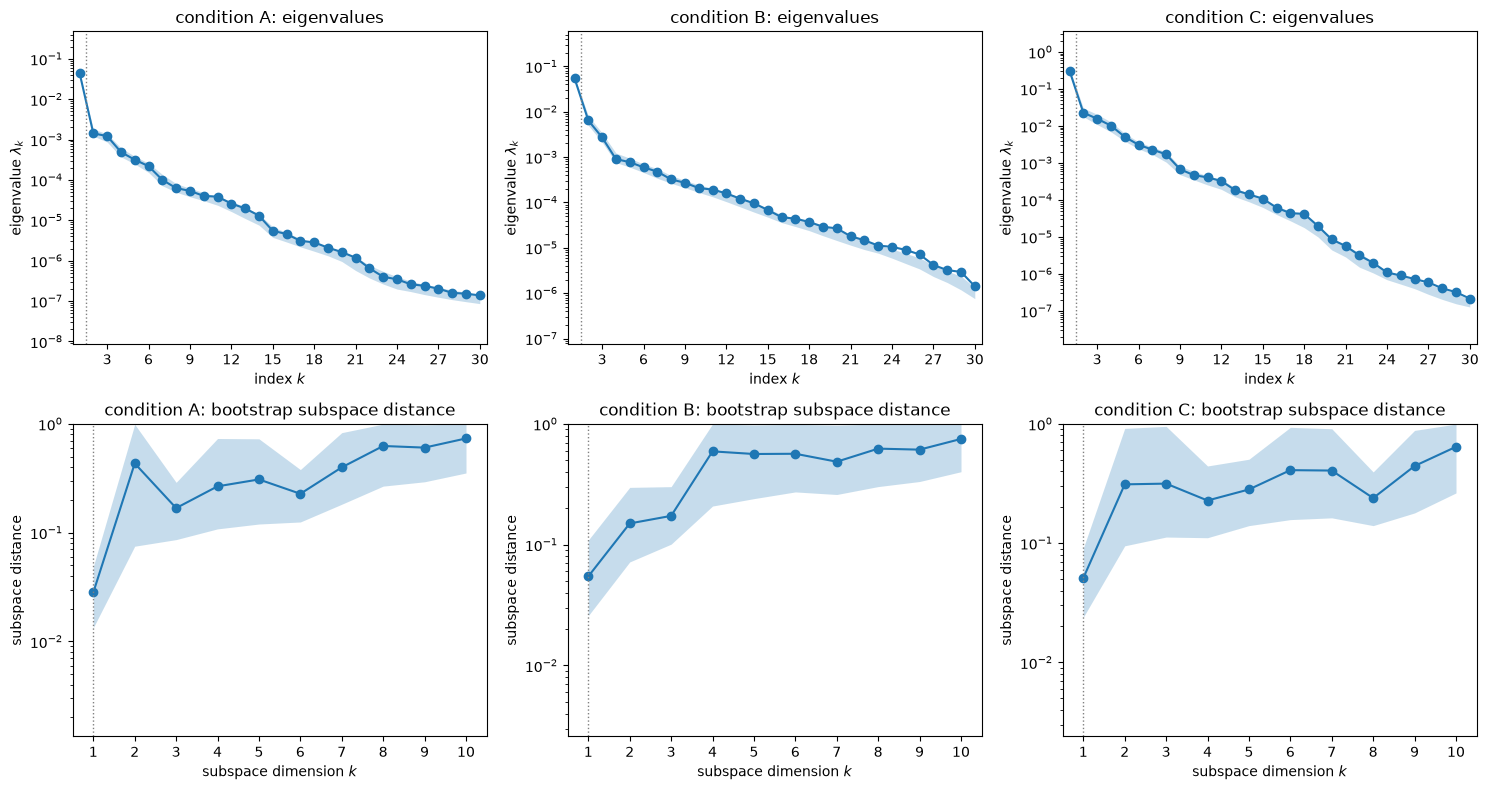

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, k in enumerate(QOIS):
    ac.plotting.plot_eigenvalues(subs[k], ax=axes[0, j], k_max=30)
    axes[0, j].set_title(f'condition {k}: eigenvalues')
    ac.plotting.plot_subspace_errors(subs[k], ax=axes[1, j], k_max=10)
    axes[1, j].set_title(f'condition {k}: bootstrap subspace distance')
fig.tight_layout(); plt.close(fig)
for k in QOIS:
    s = subs[k]
    lo, hi = ac.bootstrap_interval(s.bootstrap_eigenvalues[:, :3])
    rlo, rhi = ac.bootstrap_interval(s.bootstrap_eigenvalues[:, 0] / s.bootstrap_eigenvalues[:, 1])[:, 0]
    print(f'{k}: lambda1..3 95 % bootstrap intervals ' +
          ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi)) +
          f'; lambda1/lambda2 95 % bootstrap interval [{rlo:.1f}, {rhi:.1f}]' +
          '; mean subspace distance k = 1..4: ' + np.array2string(s.bootstrap_distances.mean(0)[:4], precision=3) +
          f'; |lambda_k| / lambda1 for k > {M}: below '
          f'{10.0 ** np.ceil(np.log10(max(np.abs(s.eigenvalues[M:]).max() / s.eigenvalues[0], 1e-17))):.0e}')
fig

At every condition the first eigenvalue stands well above the rest: $\lambda_1/\lambda_2$ = 32.0 (A), 8.5 (B) and 13.7 (C) (95 % bootstrap intervals [25.4, 37.1], [6.9, 10.6] and [10.5, 17.2]), and $\lambda_1$ alone is 0.918, 0.801 and 0.831 of the trace. The 95 % bootstrap intervals of $\lambda_1$ and $\lambda_2$ are far apart, and the mean bootstrap distance of the one-dimensional subspace is small (0.028, 0.055, 0.051) while that of the two-dimensional one is much larger (0.433, 0.15, 0.311). No second gap follows: the next ratios $\lambda_2/\lambda_3$ (1.16, 2.37, 1.46) and $\lambda_3/\lambda_4$ (2.49, 3.01, 1.54) are comparable to each other, so beyond $\mathbf w_1$ the spectrum decays slowly and no further direction is singled out; the eigenvalue-gap rule picks $n = 1$ at all three conditions. With 100 samples $\mathbf C$ has rank at most 100, and the eigenvalues beyond the 100th are at the rounding level (below 1e-17 of $\lambda_1$).

### Results: the first eigenvectors

The bars are the components of $\mathbf w_1$, three per reaction (300, 750 and 3000 K nodes, in that order). The printout sums the squared components of each reaction, the share of $\mathbf w_1$ that belongs to it.

A: share of w1^2 by reaction: R7 NH3+H=NH2+H2 0.565, R6 NH2+H(+M)=NH3(+M) 0.166, R3 NO+H(+M)=HNO(+M) 0.102, R27 N2H2+M=NNH+H+M 0.060, R19 NH+O2=HNO+O 0.031, R13 NH2+NH=N2H2+H 0.031; top 6 sum 0.954
    largest components: R07_3000K +0.566, R07_750K +0.475, R06_3000K -0.299, R03_3000K -0.289, R06_750K -0.270
    share of w1^2 by node: 300 K 0.025, 750 K 0.385, 3000 K 0.590
B: share of w1^2 by reaction: R34 H2NO+O2=HNO+HO2 0.226, R15 NH2+NO=NNH+OH 0.166, R14 NH2+NO=N2+H2O 0.135, R12 NH2+O2=H2NO+O 0.104, R36 H2NO+NH2=HNO+NH3 0.058, R16 NH2+HONO=NH3+NO2 0.042; top 6 sum 0.730
    largest components: R34_750K -0.416, R15_750K -0.295, R12_750K -0.283, R15_3000K -0.276, R14_750K +0.268
    share of w1^2 by node: 300 K 0.020, 750 K 0.691, 3000 K 0.288
C: share of w1^2 by reaction: R34 H2NO+O2=HNO+HO2 0.245, R17 NH2+NO2=N2O+H2O 0.217, R11 NH2+HO2=H2NO+OH 0.112, R18 NH2+NO2=H2NO+NO 0.097, R14 NH2+NO=N2+H2O 0.097, R15 NH2+NO=NNH+OH 0.078; top 6 sum 0.846
    largest components: R34_750K -0.476, R

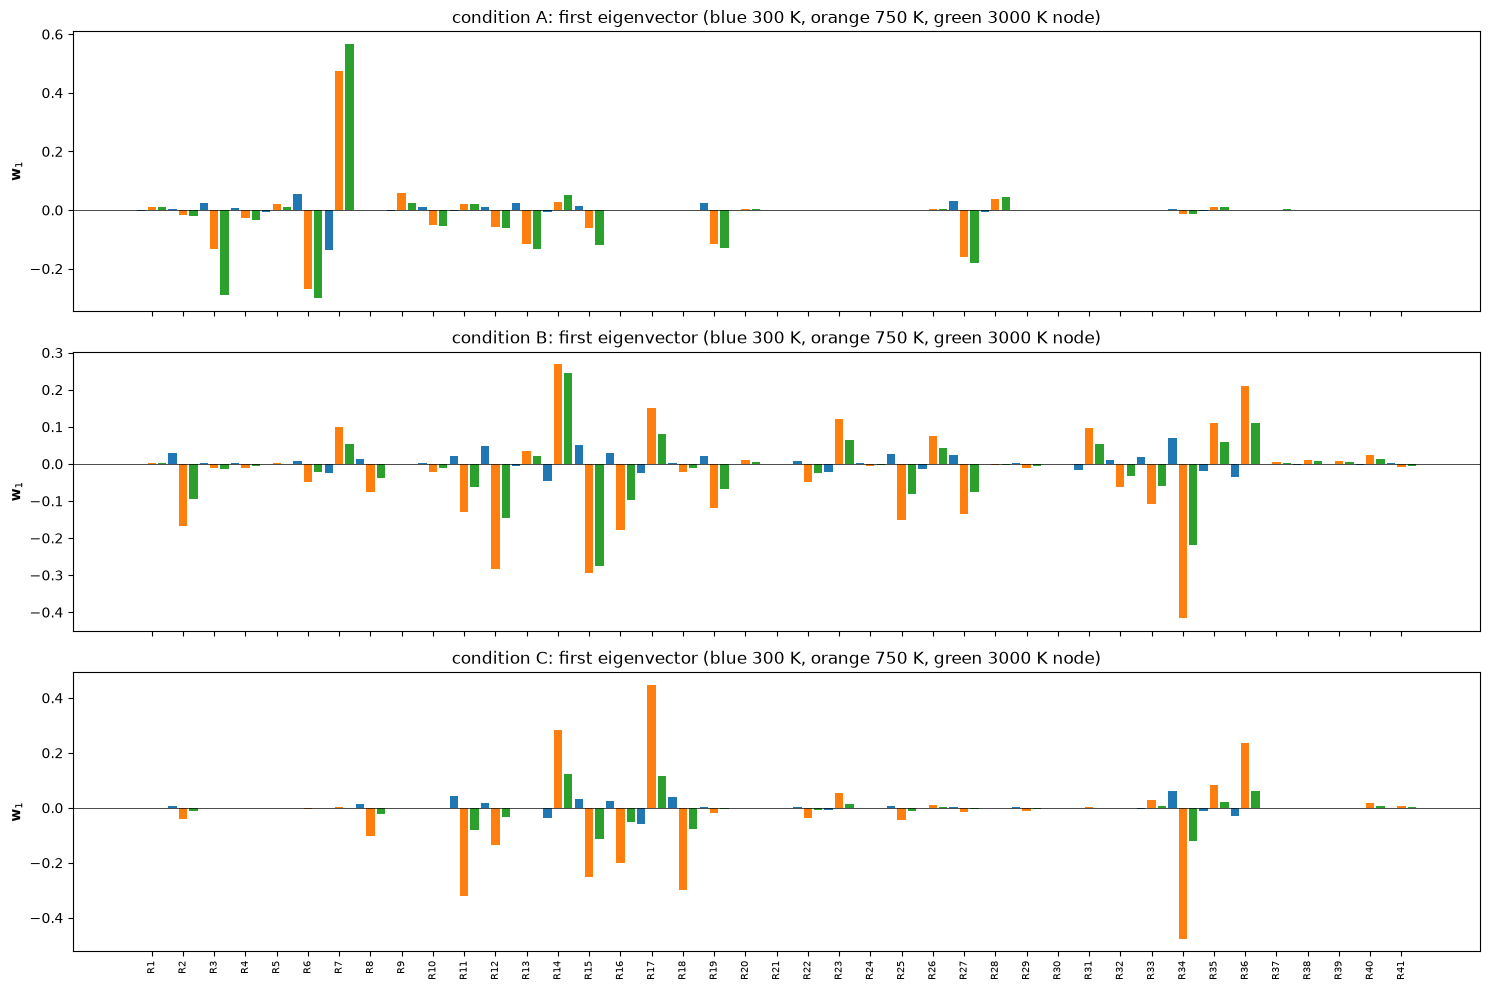

In [7]:
def per_reaction(w):
    return (w.reshape(drv.N_REACTIONS, 3) ** 2).sum(1)        # share of w1^2 on each reaction's 3 inputs

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
xs = np.arange(m)
for j, k in enumerate(QOIS):
    w = subs[k].W[:, 0]
    axes[j].bar(xs, w, color=[f'C{i % 3}' for i in range(m)])
    axes[j].axhline(0, color='k', lw=.5); axes[j].set_ylabel(r'$\mathbf{w}_1$')
    axes[j].set_title(f'condition {k}: first eigenvector (blue 300 K, orange 750 K, green 3000 K node)')
axes[-1].set_xticks(np.arange(1, m, 3)); axes[-1].set_xticklabels([f'R{r + 1}' for r in range(drv.N_REACTIONS)], rotation=90, fontsize=7)
fig.tight_layout(); plt.close(fig)
for k in QOIS:
    w = subs[k].W[:, 0]
    pr = per_reaction(w)
    o = np.argsort(-pr)
    print(f'{k}: share of w1^2 by reaction: ' + ', '.join(f'R{i + 1} {drv.REACTIONS[i]} {pr[i]:.3f}' for i in o[:6]) +
          f'; top 6 sum {pr[o[:6]].sum():.3f}')
    oc = np.argsort(-np.abs(w))[:5]
    print('    largest components: ' + ', '.join(f'{drv.NAMES[i]} {w[i]:+.3f}' for i in oc))
    print('    share of w1^2 by node: ' + ', '.join(f'{int(T)} K {(w[i::3] ** 2).sum():.3f}'
                                                   for i, T in enumerate(drv.T_NODES)))
# Sensitivity to multiplying k_r by the same factor at every temperature: the sum of reaction r's three
# node derivatives, d log10 tau / d log10 k_r. It does not depend on the choice of node temperatures.
for k in QOIS:
    sr = G[k].reshape(M, drv.N_REACTIONS, 3).sum(2).mean(0)
    o = np.argsort(-np.abs(sr))[:6]
    print(f'{k}: mean d log10 tau / d log10 k_r (uniform scaling of k_r): ' +
          ', '.join(f'R{i + 1} {drv.REACTIONS[i]} {sr[i]:+.3f}' for i in o))
print('|w1(A).w1(B)| = %.3f, |w1(A).w1(C)| = %.3f, |w1(B).w1(C)| = %.3f' % tuple(
    abs(subs[a].W[:, 0] @ subs[b].W[:, 0]) for a, b in [('A', 'B'), ('A', 'C'), ('B', 'C')]))
fig

The three conditions are controlled by different chemistry. At A (1850 K, 1.4 atm, dilute) $\mathbf w_1$ is concentrated on few reactions: NH3 + H = NH2 + H2 carries 0.565 of $\|\mathbf w_1\|^2$, NH2 + H (+M) = NH3 (+M) 0.166 and NO + H (+M) = HNO (+M) 0.102, and six reactions carry 0.954. At B and C (1400 K and 1100 K, high pressure) the weight spreads over the NH2 + NO, NH2 + NO2, NH2 + O2 and H2NO reactions, and H2NO + O2 = HNO + HO2 leads at both (B 0.226, C 0.245). The directions at B and C are similar ($|\mathbf w_1^{(B)}\cdot\mathbf w_1^{(C)}|$ = 0.769), and both are nearly orthogonal to A's (0.270, 0.064).

The signs are clearest in the mean sensitivity of $\log_{10}\tau$ to multiplying one rate constant by the same factor at every temperature, which does not depend on the node temperatures. At A a faster NH3 + H = NH2 + H2 lengthens the delay (+0.225) and a faster NH2 + H (+M) = NH3 (+M) shortens it (−0.277). The paired channels of NH2 + NO act in opposite directions at B and C: the terminating channel NH2 + NO = N2 + H2O lengthens the delay (+0.282 at B, +0.576 at C) and the chain-carrying NH2 + NO = NNH + OH shortens it (−0.313, −0.516); at C the same holds for NH2 + NO2 = N2O + H2O (+0.341) against NH2 + NO2 = H2NO + NO (−0.230). So $\log_{10}\tau$ follows the branching between the chain-carrying and the terminating channel of each pair.

How each reaction's weight is split between its three nodes is a property of the coordinates, not of the chemistry: in these coordinates most of $\|\mathbf w_1\|^2$ is at the 750 K node at B and C (0.691, 0.907) and at the 3000 K node at A (0.590), but these shares, the per-reaction shares and the eigenvalue ratios all change when the node temperatures change (the check near the end of the notebook).

### Results: sufficient summary plots and surrogates

Each panel plots $\log_{10}\tau$ against $y_1 = \mathbf w_1^T\mathbf x$ with a quadratic in $y_1$ fitted by least squares. The printout gives the leave-one-out $R^2$ of a quadratic in $y_1$ and in $(y_1, y_2)$, and the share of the eigenvalue sum that a one- and a two-dimensional subspace leave out.

A: LOO R^2 quadratic in y1 0.9448, in (y1, y2) 0.9582; eigenvalue share left out by n = 1: 0.082, by n = 2: 0.053
B: LOO R^2 quadratic in y1 0.9138, in (y1, y2) 0.9294; eigenvalue share left out by n = 1: 0.199, by n = 2: 0.105
C: LOO R^2 quadratic in y1 0.9278, in (y1, y2) 0.9390; eigenvalue share left out by n = 1: 0.169, by n = 2: 0.108


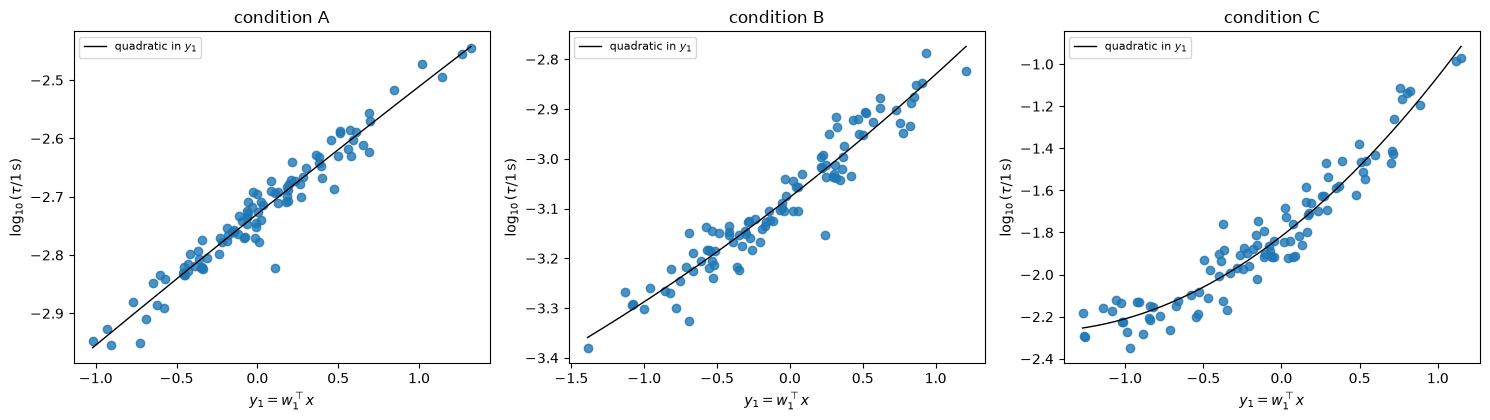

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
sur1, sur2 = {}, {}
for j, k in enumerate(QOIS):
    s = subs[k]
    sur1[k] = ac.fit_surrogate(X=X, f=F[k], subspace=s, kind='poly', degree=2)
    s2 = ac.with_dimension(s, 2)
    sur2[k] = ac.fit_surrogate(X=X, f=F[k], subspace=s2, kind='poly', degree=2)
    ac.plotting.plot_sufficient_summary(s, X=X, f=F[k], dims=1, qoi_label=r'$\log_{10}(\tau/1\,\mathrm{s})$', ax=axes[j])
    y = space.to_normalized(X) @ s.W[:, 0]
    yy = np.linspace(y.min(), y.max(), 200)
    axes[j].plot(yy, sur1[k].evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $y_1$')
    axes[j].legend(fontsize=8); axes[j].set_title(f'condition {k}')
fig.tight_layout(); plt.close(fig)
for k in QOIS:
    lam = subs[k].eigenvalues
    print(f'{k}: LOO R^2 quadratic in y1 {sur1[k].loo_r_squared:.4f}, in (y1, y2) {sur2[k].loo_r_squared:.4f}; '
          f'eigenvalue share left out by n = 1: {lam[1:].sum() / lam.sum():.3f}, by n = 2: {lam[2:].sum() / lam.sum():.3f}')
fig

The summary plots show tight one-dimensional trends, nearly linear at A and B and convex at C. A quadratic in $y_1$ has leave-one-out $R^2$ 0.9448 (A), 0.9138 (B) and 0.9278 (C); adding $y_2$ raises it only to 0.9582, 0.9294 and 0.9390. The one-dimensional subspace leaves out 0.082, 0.199 and 0.169 of the eigenvalue sum, the two-dimensional one 0.053, 0.105 and 0.108. **Dimension: $n = 1$ at all three conditions**, from the gap $\lambda_1/\lambda_2$ with the small bootstrap distance at $n = 1$, the absence of a later gap, and the small gain in $R^2$ from a second variable. Condition B is the weakest case: its first ratio is the smallest, and about a fifth of the eigenvalue sum lies outside $\mathbf w_1$, spread over many directions.

### Sampling check: two halves of the design

The first and second halves of the rows are two independent Monte Carlo designs. If 100 samples suffice for the leading direction, the two halves should give nearly the same $\mathbf w_1$.

In [9]:
# Sampling check: the leading eigenvalue ratio from the first half and the second half of the rows,
# and the angle between their first eigenvectors.
half = M // 2
for k in QOIS:
    out = []
    for sl in (slice(0, half), slice(half, M)):
        r_ = ac.active_subspace(space=space, X=X[sl], f=F[k][sl], grads=G[k][sl], estimator='as', n=1)
        out.append(r_)
    l0, l1 = out[0].eigenvalues, out[1].eigenvalues
    print(f'{k}: lambda1/lambda2 = {l0[0] / l0[1]:.1f} (rows 0-{half - 1}) and {l1[0] / l1[1]:.1f} (rows {half}-{M - 1}); '
          f'|w1 . w1| between halves {abs(out[0].W[:, 0] @ out[1].W[:, 0]):.3f}, '
          f'against the full set {abs(out[0].W[:, 0] @ subs[k].W[:, 0]):.3f} and {abs(out[1].W[:, 0] @ subs[k].W[:, 0]):.3f}')

A: lambda1/lambda2 = 32.1 (rows 0-49) and 31.0 (rows 50-99); |w1 . w1| between halves 0.999, against the full set 1.000 and 1.000
B: lambda1/lambda2 = 10.0 (rows 0-49) and 7.4 (rows 50-99); |w1 . w1| between halves 0.997, against the full set 0.999 and 0.999
C: lambda1/lambda2 = 10.4 (rows 0-49) and 17.1 (rows 50-99); |w1 . w1| between halves 0.997, against the full set 0.999 and 0.999


The two halves agree: $|\mathbf w_1\cdot\mathbf w_1|$ between them is 0.999 (A), 0.997 (B) and 0.997 (C), and against the full-data $\mathbf w_1$ it is 1.000 (A) and 0.999 (B, C) for both halves, to three digits. The ratio $\lambda_1/\lambda_2$ varies more between halves (A 32.1 and 31.0, B 10.0 and 7.4, C 10.4 and 17.1), so the size of the gap is less certain than its direction, but every half shows it.

### Sensitivity to the node temperatures

The nodes 300, 750 and 3000 K are this data set's choice. For other nodes $T'_i$ the coordinates of each reaction are $\mathbf x'_r = \mathbf P\mathbf x_r$ with $\mathbf P = \mathbf B(T')\mathbf B(T)^{-1}$, where the rows of $\mathbf B$ are $(1, \ln T_i, -1/T_i)/\ln 10$; the samples stay uniform on the same region, and the gradients transform exactly, $\nabla_{\mathbf x'_r} f = \mathbf P^{-T}\nabla_{\mathbf x_r} f$. Only the scaling to $[-1, 1]$ changes, since each input is then scaled by $f_r(T'_i)$. The next cell repeats the eigen-analysis for five other node sets with the same samples and no new Cantera runs.

In [10]:
# Same samples and gradients, other node temperatures: x'_r = P x_r, grad' = P^-T grad, scaling by f_r(T').
NODE_SETS = [(300, 750, 3000), (300, 500, 3000), (300, 1000, 3000), (300, 1200, 3000), (400, 1000, 2000),
             (500, 1500, 2500)]
nr = drv.N_REACTIONS
for nodes in NODE_SETS:
    Pm = drv.basis(np.array(nodes, float)) @ drv.NODE_INV
    Pinv = np.linalg.inv(Pm)
    U1 = np.array([drv.f_of_T(r, T) for r in range(nr) for T in nodes], float)
    X1 = (X.reshape(M, nr, 3) @ Pm.T).reshape(M, -1)
    space1 = ac.Uniform(-U1, U1)
    w1s, line = {}, []
    for k in QOIS:
        G1 = (G[k].reshape(M, nr, 3) @ Pinv).reshape(M, -1)
        s1 = ac.active_subspace(space=space1, X=X1, f=F[k], grads=G1, estimator='as', n=1)
        lam, w = s1.eigenvalues, s1.W[:, 0]
        w1s[k] = w
        pr = per_reaction(w)
        o = np.argsort(-pr)[:3]
        line.append(f'{k}: l1/l2 {lam[0] / lam[1]:4.1f}, l2/l3 {lam[1] / lam[2]:.2f}; ' +
                    ', '.join(f'R{i + 1} {pr[i]:.3f}' for i in o) +
                    f'; middle node {(w[1::3] ** 2).sum():.3f}')
    ov = [abs(w1s[a] @ w1s[b]) for a, b in [('A', 'B'), ('A', 'C'), ('B', 'C')]]
    print(f'nodes {nodes} K: ' + ' | '.join(line) + '; |w1.w1| AB %.3f AC %.3f BC %.3f' % tuple(ov))

nodes (300, 750, 3000) K: A: l1/l2 32.0, l2/l3 1.16; R7 0.565, R6 0.166, R3 0.102; middle node 0.385 | B: l1/l2  8.5, l2/l3 2.37; R34 0.226, R15 0.166, R14 0.135; middle node 0.691 | C: l1/l2 13.7, l2/l3 1.46; R34 0.245, R17 0.217, R11 0.112; middle node 0.907; |w1.w1| AB 0.270 AC 0.064 BC 0.769
nodes (300, 500, 3000) K: A: l1/l2 36.6, l2/l3 1.25; R7 0.639, R6 0.143, R3 0.078; middle node 0.456 | B: l1/l2  8.5, l2/l3 2.38; R34 0.226, R15 0.161, R14 0.132; middle node 0.620 | C: l1/l2 13.7, l2/l3 1.45; R34 0.244, R17 0.216, R11 0.112; middle node 0.779; |w1.w1| AB 0.283 AC 0.064 BC 0.781
nodes (300, 1000, 3000) K: A: l1/l2 29.2, l2/l3 1.20; R7 0.523, R6 0.184, R3 0.108; middle node 0.446 | B: l1/l2  8.2, l2/l3 2.37; R34 0.238, R15 0.149, R14 0.121; middle node 0.834 | C: l1/l2 13.5, l2/l3 1.47; R34 0.249, R17 0.221, R11 0.115; middle node 0.986; |w1.w1| AB 0.256 AC 0.057 BC 0.762
nodes (300, 1200, 3000) K: A: l1/l2 26.4, l2/l3 1.22; R7 0.468, R6 0.209, R3 0.120; middle node 0.546 | B: l

nodes (400, 1000, 2000) K: A: l1/l2 24.0, l2/l3 1.12; R7 0.398, R6 0.198, R3 0.192; middle node 0.025 | B: l1/l2  9.1, l2/l3 2.37; R34 0.210, R15 0.195, R14 0.157; middle node 0.505 | C: l1/l2 13.5, l2/l3 1.47; R34 0.248, R17 0.219, R11 0.114; middle node 0.962; |w1.w1| AB 0.240 AC 0.036 BC 0.672
nodes (500, 1500, 2500) K: A: l1/l2 23.5, l2/l3 1.14; R7 0.364, R6 0.243, R3 0.157; middle node 0.613 | B: l1/l2  8.6, l2/l3 2.41; R34 0.225, R15 0.174, R14 0.145; middle node 0.997 | C: l1/l2 14.3, l2/l3 1.40; R34 0.227, R17 0.198, R14 0.134; middle node 0.916; |w1.w1| AB 0.216 AC 0.059 BC 0.796


Across the six node sets the dimension and the ranking of the leading reactions hold: $\lambda_1/\lambda_2$ stays far above $\lambda_2/\lambda_3$ (A 23.5–36.6 against 1.12–1.25, B 7.9–9.1 against 2.37–2.41, C 13.5–14.3 against 1.40–1.47), so $n = 1$ in every case; NH3 + H = NH2 + H2, NH2 + H (+M) = NH3 (+M) and NO + H (+M) = HNO (+M) are the first three reactions at A; and H2NO + O2 = HNO + HO2 leads at B and C, followed by NH2 + NO = NNH + OH at B and NH2 + NO2 = N2O + H2O at C. The B and C directions stay close ($|\mathbf w_1^{(B)}\cdot\mathbf w_1^{(C)}|$ 0.672–0.796), and A's stays nearly orthogonal to both (at most 0.283 and 0.064). What changes is how the weight is distributed: NH3 + H = NH2 + H2 carries 0.364 to 0.639 of $\|\mathbf w_1\|^2$ at A, and the middle node carries 0.025–0.613 at A, 0.505–0.997 at B and 0.779–0.998 at C. So the node shares, the per-reaction shares and the exact ratios quoted above belong to the 300, 750 and 3000 K coordinates; at A the ratio moves with the nodes by about as much as its bootstrap interval ([25.4, 37.1]) is wide.

### Comparison with the paper

The paper reports no active subspace, sensitivity indices or uncertainty propagation for these quantities, so the comparison is limited to the model itself: the mechanism file against Table 2, and the delay at the optimized point against ESI Fig. S14. The delays at $\mathbf x = 0$ below were computed with the driver when the data were made; `check_accuracy.py` recomputes them where Cantera is installed.

In [11]:
# tau at the optimized model (x = 0): computed with ammonia_idt_driver.IgnitionModel (Cantera 3.2.0)
# when the data were made; check_accuracy.py recomputes them where Cantera is installed (DATA.md).
TAU0_MS = {'A': 1.8703, 'B': 0.8175, 'C': 15.1083}
for q, k in enumerate(QOIS):
    print(f'{k}: tau(x = 0) = {TAU0_MS[k]:.4f} ms (stored value); over the samples median '
          f'{np.median(tau[:, q]) * 1e3:.4f} ms, 2.5-97.5 % {np.percentile(tau[:, q], 2.5) * 1e3:.3f}-'
          f'{np.percentile(tau[:, q], 97.5) * 1e3:.3f} ms')
print(f'notebook run time {time.perf_counter() - t_start:.0f} s')

A: tau(x = 0) = 1.8703 ms (stored value); over the samples median 1.8722 ms, 2.5-97.5 % 1.154-3.290 ms
B: tau(x = 0) = 0.8175 ms (stored value); over the samples median 0.7698 ms, 2.5-97.5 % 0.500-1.413 ms
C: tau(x = 0) = 15.1083 ms (stored value); over the samples median 12.9945 ms, 2.5-97.5 % 5.172-75.800 ms
notebook run time 86 s


| quantity | paper (page) | this notebook |
|---|---|---|
| inputs | 123 Arrhenius parameters, $(\alpha, \beta, \varepsilon)$ of 41 reactions, region eqn (4)–(5) (pp. 2074–2075, Table 2) | 123 node coordinates, a linear reparametrization of the same $(\alpha, \beta, \varepsilon)$, region centred on $k^*$ instead of $k_0$ |
| $\tau$ at A, optimized model | about 1.9 ms at 1850 K, read from ESI Fig. S14a (ESI p. 7) by digitizing the figure | 1.8703 ms |
| $\tau$ at C, optimized model | about 19 ms at 1100 K, read from ESI Fig. S14b (ESI p. 7) by digitizing the figure; RCM volume profile | 15.1083 ms (constant volume, no heat loss) |
| $\tau$ at B, optimized model | not reported | 0.8175 ms |
| $E^*$ of NH2 + H = NH + H2 | $3.564\times10^{4}$ cal/mol (Table 2, p. 2076) | $3.5639\times10^{3}$ cal/mol in the ESI mechanism file, used here |
| spread of $\tau$ over the uncertainty region | not reported | 2.5–97.5 % ranges: 1.154–3.290 ms (A), 0.500–1.413 ms (B), 5.172–75.800 ms (C) |
| active subspace, global sensitivity | not reported | $n = 1$ at A, B and C; $\lambda_1/\lambda_2$ = 32.0, 8.5, 13.7 |
| reactions that matter most | not reported for $\tau$; the largest adjustment, 78.1 %, is NH3 (+M) = NH2 + H (+M) (p. 2076) | A: NH3 + H = NH2 + H2; B and C: H2NO + O2 = HNO + HO2 and the NH2 + NO / NH2 + NO2 channels |

At A the delay of the converted mechanism matches the optimized-model curve of Fig. S14a to within the accuracy of reading the figure. At C it is shorter than the curve of Fig. S14b, as expected when the reactor has no heat loss after compression. The paper's Table 2 and the ESI mechanism disagree in one activation energy by a factor of ten; the file's value is used, and the comparison above cannot say which is intended. The reaction with the paper's largest adjustment, NH3 (+M) = NH2 + H (+M) (R06, written here in the recombination direction), is the second reaction of $\mathbf w_1$ at A (0.166 of $\|\mathbf w_1\|^2$); adjustment size and influence on $\tau$ at three conditions are different measures, so no closer agreement is to be expected.

### References

[1] W. Li, C. Zou, and H. Yao. [An optimized model for ammonia/syngas combustion](https://doi.org/10.1039/D3RE00160A). *Reaction Chemistry & Engineering*, 8(8):2071–2085, 2023. Electronic supplementary information: the optimized mechanism in CHEMKIN format, Tables S1–S3 and Figs. S1–S15.

[2] O. Mathieu and E. L. Petersen. [Experimental and modeling study on the high-temperature oxidation of Ammonia and related NOx chemistry](https://doi.org/10.1016/j.combustflame.2014.08.022). *Combustion and Flame*, 162(3):554–570, 2015.

[3] B. Shu, S. K. Vallabhuni, X. He, G. Issayev, K. Moshammer, A. Farooq, and R. X. Fernandes. [A shock tube and modeling study on the autoignition properties of ammonia at intermediate temperatures](https://doi.org/10.1016/j.proci.2018.07.074). *Proceedings of the Combustion Institute*, 37(1):205–211, 2019.

[4] X. He, B. Shu, D. Nascimento, K. Moshammer, M. Costa, and R. X. Fernandes. [Auto-ignition kinetics of ammonia and ammonia/hydrogen mixtures at intermediate temperatures and high pressures](https://doi.org/10.1016/j.combustflame.2019.04.050). *Combustion and Flame*, 206:189–200, 2019.

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[6] D. G. Goodwin, H. K. Moffat, I. Schoegl, R. L. Speth, and B. W. Weber. Cantera: An object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes. Version 3.2.0, https://www.cantera.org.

### Acknowledgments

The paper [1, p. 2083] states: "This work was supported by the National Natural Science Foundation of China (Grant No. 52206146 and 52276111)."